In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('data of gurugram real Estate.csv')
print(df.head())

      Price              Status  Area Rate per sqft  \
0  10700000  Under Construction  1138         9,450   
1  14400000  Under Construction  1528         9,450   
2  10700000  Under Construction  1138         9,450   
3  40000000       Ready to move  4500         8,888   
4  24000000  Under Construction  1800        13,333   

                                       Property Type   Locality  \
0       2 BHK Apartment in M3M Antalya Hills Phase I  Sector 79   
1       3 BHK Apartment in M3M Antalya Hills Phase I  Sector 79   
2       2 BHK Apartment in M3M Antalya Hills Phase I  Sector 79   
3                            4 BHK Independent Floor  Sector 57   
4  3 BHK Independent Floor in Anant Raj Estate Plots  Sector 63   

                     Builder Name         RERA Approval  BHK_Count  \
0                            home      Approved by RERA          2   
1             Property In Gurgaon      Approved by RERA          3   
2  properties for sale in Gurgaon      Approved by RERA 

In [3]:
print(df.columns.tolist())

['Price', 'Status', 'Area', 'Rate per sqft', 'Property Type', 'Locality', 'Builder Name', 'RERA Approval', 'BHK_Count', 'Society', 'Company Name', 'Flat Type']


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19515 entries, 0 to 19514
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Price          19515 non-null  object
 1   Status         19515 non-null  object
 2   Area           19515 non-null  int64 
 3   Rate per sqft  19515 non-null  object
 4   Property Type  19515 non-null  object
 5   Locality       19515 non-null  object
 6   Builder Name   19515 non-null  object
 7   RERA Approval  19515 non-null  object
 8   BHK_Count      19515 non-null  int64 
 9   Society        19515 non-null  object
 10  Company Name   19515 non-null  object
 11  Flat Type      19515 non-null  object
dtypes: int64(2), object(10)
memory usage: 1.8+ MB


# Data Cleaning


In [5]:
df.columns=df.columns.str.strip().str.lower().str.replace(" ", "_")
print(df.columns.tolist())

['price', 'status', 'area', 'rate_per_sqft', 'property_type', 'locality', 'builder_name', 'rera_approval', 'bhk_count', 'society', 'company_name', 'flat_type']


In [6]:
df=df.drop_duplicates()
df

,price,status,area,rate_per_sqft,property_type,locality,builder_name,rera_approval,bhk_count,society,company_name,flat_type
0,10700000,Under Construction,1138,"9,450",2 BHK Apartment in M3M Antalya Hills Phase I,Sector 79,home,Approved by RERA,2,M3M Antalya Hills Phase I,M3M,Apartment
1,14400000,Under Construction,1528,"9,450",3 BHK Apartment in M3M Antalya Hills Phase I,Sector 79,Property In Gurgaon,Approved by RERA,3,M3M Antalya Hills Phase I,M3M,Apartment
2,10700000,Under Construction,1138,"9,450",2 BHK Apartment in M3M Antalya Hills Phase I,Sector 79,properties for sale in Gurgaon,Approved by RERA,2,M3M Antalya Hills Phase I,M3M,Apartment
3,40000000,Ready to move,4500,"8,888",4 BHK Independent Floor,Sector 57,MM India Pvt Ltd,Not approved by RERA,4,Outside Socity,Outside,Plot
4,24000000,Under Construction,1800,"13,333",3 BHK Independent Floor in Anant Raj Estate Plots,Sector 63,MM India Pvt Ltd,Approved by RERA,3,Anant Raj Estate Plots,Anant,Floor
...,...,...,...,...,...,...,...,...,...,...,...,...
19510,24100000,Ready to move,1381,"17,500",2 BHK Apartment in Sobha City,Sector 108,Shree Realstic One,Not approved by RERA,2,Sobha City,Sobha,Apartment
19511,36200000,Ready to move,2072,"17,500",3 BHK Apartment in Sobha City,Sector 108,Shree Realstic One,Not approved by RERA,3,Sobha City,Sobha,Apartment
19512,39100000,Under Construction,2445,"16,002",3 BHK Apartment in Pyramid Alban,Sector 71,Shree Realstic One,Approved by RERA,3,Pyramid Alban,Pyramid,Apartment
19513,37700000,Under Construction,2360,"16,001",3 BHK Apartment in Pyramid Alban,Sector 71,Shree Realstic One,Approved by RERA,3,Pyramid Alban,Pyramid,Apartment


# Numerical Columns Cleaning

In [7]:
df['price']=df['price'].astype(str).str.replace(",","").astype(float)
print(df['price'])

0        10700000.0
1        14400000.0
2        10700000.0
3        40000000.0
4        24000000.0
            ...    
19510    24100000.0
19511    36200000.0
19512    39100000.0
19513    37700000.0
19514    36500000.0
Name: price, Length: 14223, dtype: float64


In [8]:
df['area']=df['area'].astype(str).str.replace(",","").astype('int64')
print(df['area'])

0        1138
1        1528
2        1138
3        4500
4        1800
         ... 
19510    1381
19511    2072
19512    2445
19513    2360
19514    2282
Name: area, Length: 14223, dtype: int64


In [9]:
df['rate_per_sqft'] = df['rate_per_sqft'].astype(str).str.replace(",", "").astype('int64')
print(df['rate_per_sqft'])


0         9450
1         9450
2         9450
3         8888
4        13333
         ...  
19510    17500
19511    17500
19512    16002
19513    16001
19514    16005
Name: rate_per_sqft, Length: 14223, dtype: int64


# Categorical Columns Cleaning

In [10]:
df['status'] = df['status'].str.strip().str.lower()

df['rera_approval'] = (
    df['rera_approval']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        'approved by rera': True,
        'not approved by rera': False
    })
)

print(df['rera_approval'])


0         True
1         True
2         True
3        False
4         True
         ...  
19510    False
19511    False
19512     True
19513     True
19514     True
Name: rera_approval, Length: 14223, dtype: bool


In [11]:
df['flat_type'] = df['flat_type'].str.strip().str.lower()

In [12]:
df=df.drop_duplicates()
print(df)

            price              status  area  rate_per_sqft  \
0      10700000.0  under construction  1138           9450   
1      14400000.0  under construction  1528           9450   
2      10700000.0  under construction  1138           9450   
3      40000000.0       ready to move  4500           8888   
4      24000000.0  under construction  1800          13333   
...           ...                 ...   ...            ...   
19510  24100000.0       ready to move  1381          17500   
19511  36200000.0       ready to move  2072          17500   
19512  39100000.0  under construction  2445          16002   
19513  37700000.0  under construction  2360          16001   
19514  36500000.0  under construction  2282          16005   

                                           property_type    locality  \
0           2 BHK Apartment in M3M Antalya Hills Phase I   Sector 79   
1           3 BHK Apartment in M3M Antalya Hills Phase I   Sector 79   
2           2 BHK Apartment in M3M Anta

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14223 entries, 0 to 19514
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          14223 non-null  float64
 1   status         14223 non-null  object 
 2   area           14223 non-null  int64  
 3   rate_per_sqft  14223 non-null  int64  
 4   property_type  14223 non-null  object 
 5   locality       14223 non-null  object 
 6   builder_name   14223 non-null  object 
 7   rera_approval  14223 non-null  bool   
 8   bhk_count      14223 non-null  int64  
 9   society        14223 non-null  object 
 10  company_name   14223 non-null  object 
 11  flat_type      14223 non-null  object 
dtypes: bool(1), float64(1), int64(3), object(7)
memory usage: 1.3+ MB


# Bussiness Questions

In [14]:
# 1. Which is the costliest flat in the dataset?
costliest_flat = df.loc[df['price'].idxmax()]
costliest_flat

price                                1226300000.0
status                              ready to move
area                                        16500
rate_per_sqft                               74323
property_type    6 BHK Apartment in DLF Camellias
locality                                Sector 42
builder_name                    Provident Capital
rera_approval                               False
bhk_count                                       6
society                             DLF Camellias
company_name                                  DLF
flat_type                               apartment
Name: 2839, dtype: object

In [15]:
# Let's write this as a sentence:
print(f"The costliest flat is a {costliest_flat['bhk_count']} BHK flat located in {costliest_flat['locality']} priced at {costliest_flat['price']/10000000} in {costliest_flat['society']} society.")

The costliest flat is a 6 BHK flat located in Sector 42 priced at 122.63 in  DLF Camellias society.


In [16]:
# 2. Which locality has the highest average price?
highest_avg_price_locality = df.groupby('locality')['price'].mean().idxmax()
f"The locality with the highest average price is {highest_avg_price_locality}."

'The locality with the highest average price is Baliawas.'

In [17]:
# 3. Which locality has the highest rate per square foot?
highest_rate_locality = df.groupby('locality')['rate_per_sqft'].mean().idxmax()
f"The locality with the highest rate per square foot is {highest_rate_locality}."

'The locality with the highest rate per square foot is Sector 42.'

In [18]:
# 4. Do ready-to-move properties cost more than under-construction properties?
ready_to_move_avg_price = df[df['status'] == 'ready to move']['price'].mean()
under_construction_avg_price = df[df['status']=='under construction']['price'].mean()
if ready_to_move_avg_price > under_construction_avg_price:
    print("Ready-to-move properties cost more on average than under-construction properties.")
else:
    print("Under-construction properties cost more on average than ready-to-move properties.")

Ready-to-move properties cost more on average than under-construction properties.


In [19]:
# 5. Do RERA-approved properties command a price premium?
rera_approved_avg_price = df[df['rera_approval']==True]['price'].mean()
rera_not_approved_avg_price = df[df['rera_approval']==True]['price'].mean()
if rera_approved_avg_price>rera_not_approved_avg_price:
    print("RERA-approved properties command a price premium.")
else:
    print("RERA-approved properties do not command a price premium.")

RERA-approved properties do not command a price premium.


<Axes: xlabel='area', ylabel='price'>

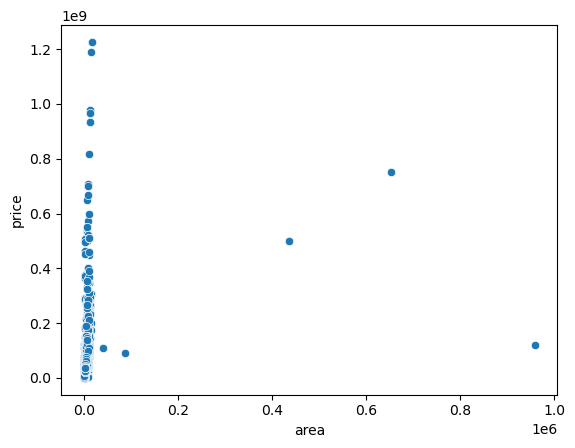

In [20]:
# 6. How does area (sqft) impact property price?
sns.scatterplot(data=df, x='area', y='price')


In [21]:
# 7. Which BHK configuration is the most expensive on average?
most_expesive_bhk = df.groupby('bhk_count')['rate_per_sqft'].mean().idxmax()
f"The most expensive BHK configuration on average is {most_expesive_bhk} BHK."

'The most expensive BHK configuration on average is 114 BHK.'

In [22]:
# 8. Which property type (Apartment, Floor, Plot) is the costliest?
most_expensive_property_type = df.groupby('flat_type')['rate_per_sqft'].mean().idxmax()
f"The most expensive property type is {most_expensive_property_type}."

'The most expensive property type is villa.'

In [23]:
# 9. Do certain builders or companies consistently price higher?
print(df.groupby("company_name")["rate_per_sqft"].mean().sort_values(ascending=False).head(5))
# Print name of top 5
top_5_builders = df.groupby("company_name")["rate_per_sqft"].mean().sort_values(ascending=False).head(5)

# Optional: print the series with the average rates
print(top_5_builders)

# Print name of top 5
print("\nThe top 5 builders that price higher are:", end=" ")
for builder in top_5_builders.index:
    print(builder, end=", ")


company_name
Camelliaass    44724.333333
Cameliaas      40000.000000
Tulip          28571.121495
Prom           27358.600000
Magnoliaass    26666.000000
Name: rate_per_sqft, dtype: float64
company_name
Camelliaass    44724.333333
Cameliaas      40000.000000
Tulip          28571.121495
Prom           27358.600000
Magnoliaass    26666.000000
Name: rate_per_sqft, dtype: float64

The top 5 builders that price higher are: Camelliaass, Cameliaas, Tulip, Prom, Magnoliaass, 

<Axes: xlabel='area', ylabel='rate_per_sqft'>

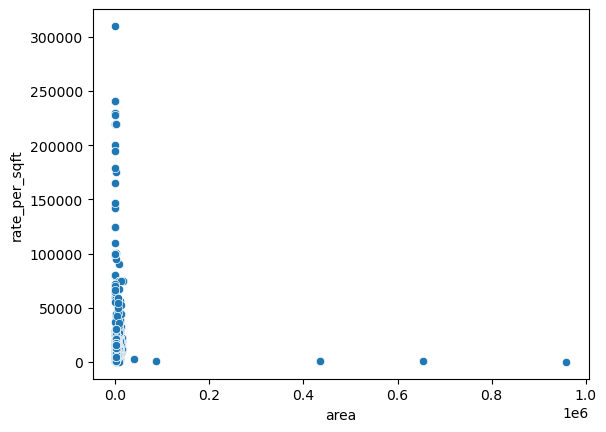

In [24]:
# 10. Are larger homes always more expensive per square foot?
sns.scatterplot(data=df, x="area", y="rate_per_sqft")